# 📊 BÁO CÁO TOÀN DIỆN: KHÁM PHÁ DỮ LIỆU (EDA) & THỐNG KÊ SUY DIỄN
## DỰ ĐOÁN CHIẾN THUẬT & TỶ LỆ THẮNG SỚM 2 GIAI ĐOẠN - LIÊN MINH HUYỀN THOẠI (LMHT)

> **Môn học:** Nhập môn Khoa học Dữ liệu (Introduction to Data Science)  
> **Học viện Công nghệ Bưu chính Viễn thông (PTIT)**  
> **Giảng viên hướng dẫn:** TS. Thái Tuyết Hải  
> **Cơ sở dữ liệu:** `data/database/lol_live_data.db` (37,009 bản ghi chuẩn 1NF/3NF)  
> **Nội dung bao phủ:** Chương 1 (Thống kê suy diễn), Chương 2 (Làm sạch dữ liệu), Chương 3 (Trực quan hóa EDA), Chương 5 & 5x (Cơ sở dữ liệu SQL & Pandas)

---

### 📑 CẤU TRÚC NỘI DUNG NOTEBOOK:
1. **Phần 1: Khởi tạo Môi trường & Tổng quan CSDL SQLite (Chương 2, 5)**
2. **Phần 2: 5 Câu Truy Vấn SQL Phân Tích Nâng Cao (Chương 5 & 5x)**
3. **Phần 3: Thống Kê Suy Diễn & 3 Bài Kiểm Định Giả Thuyết (Chương 1)**
   * *Kiểm định 1:* Two-sample Proportion Z-test Lợi thế Phe Xanh (Blue Side Advantage).
   * *Kiểm định 2:* Two-sample Welch's t-test & Z-test Lăn Cầu Tuyết (Snowball Lead >= 2,000g).
   * *Kiểm định 3:* Chi-square test (χ²) & Odds Ratio: 3 Sâu Hư Không vs Rồng 1.
4. **Phần 4: Bộ 5 Biểu Đồ Trực Quan Hóa EDA Chuẩn 300 DPI (Chương 3)**
   * *Fig 1:* Ma trận tương quan tuyến tính Pearson Heatmap (9x9).
   * *Fig 2:* Phân phối chênh lệch vàng phút 10 (Histogram + KDE Density).
   * *Fig 3:* Phân bố kinh tế 5 vị trí thi đấu (Boxplot & Outliers 1.5 IQR).
   * *Fig 4:* Quan hệ Vàng dẫn trước 10p vs Thời lượng trận đấu (Scatter + OLS).
   * *Fig 5:* Ma trận toàn diện 8 tổ hợp mục tiêu lớn (Grouped Bar 2 Subplots).
5. **Phần 5: Tổng Kết Insights Khoa Học & Khuyến Nghị Cho Giai Đoạn 3 (Machine Learning)**


In [1]:
import sys
import sqlite3
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

warnings.filterwarnings('ignore')

# Cấu hình hiển thị Pandas
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

# Cấu hình đồ họa Matplotlib & Seaborn
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI', 'Helvetica']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="deep")

# Đường dẫn CSDL và thư mục figures
DB_PATH = Path("../data/database/lol_live_data.db")
if not DB_PATH.exists():
    DB_PATH = Path("data/database/lol_live_data.db")

FIGURES_DIR = Path("../reports/figures")
if not FIGURES_DIR.exists():
    FIGURES_DIR = Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅ Đã kết nối thư viện thành công.")
print(f"📁 Đường dẫn CSDL: {DB_PATH.resolve()}")
print(f"🖼️ Đường dẫn Figures: {FIGURES_DIR.resolve()}")


✅ Đã kết nối thư viện thành công.
📁 Đường dẫn CSDL: D:\Chivinh\2026_MonHoc\Nhập môn khoa học dữ liệu\Project\data\database\lol_live_data.db
🖼️ Đường dẫn Figures: D:\Chivinh\2026_MonHoc\Nhập môn khoa học dữ liệu\Project\reports\figures


---
## 1. TỔNG QUAN CƠ SỞ DỮ LIỆU SQLITE & TIỀN XỬ LÝ (CHƯƠNG 2, 5)

Dự án tích hợp 2 nguồn dữ liệu lớn được thiết kế chuẩn hóa 1NF/3NF vào CSDL SQLite `lol_live_data.db`:
* **Bảng `matches_10min`:** 1,009 trận Rank Cao (Thách Đấu VN & Hàn Quốc) bóc tách đúng mốc 10 phút qua Riot Games API.
* **Bảng `tournament_matches`:** 6,000 bản ghi đội (3,000 trận đỉnh cao LCK, LPL, LCP, MSI, Worlds) từ Oracle's Elixir.
* **Bảng `tournament_players`:** 30,000 bản ghi 10 vị trí tuyển thủ mốc 10 phút.


In [2]:
conn = sqlite3.connect(DB_PATH)

# Kiểm tra tổng số dòng của từng bảng
tables_info = []
for tbl in ['matches_10min', 'tournament_matches', 'tournament_players']:
    cursor = conn.cursor()
    cursor.execute(f"SELECT COUNT(*) FROM {tbl}")
    count = cursor.fetchone()[0]
    cursor.execute(f"PRAGMA table_info({tbl})")
    cols = len(cursor.fetchall())
    tables_info.append({"Bảng CSDL": tbl, "Số Cột": cols, "Tổng Số Bản Ghi": f"{count:,} dòng"})

df_tables = pd.DataFrame(tables_info)
print("=" * 60)
print("📊 QUY MÔ CƠ SỞ DỮ LIỆU LOL_LIVE_DATA.DB (37,009 BẢN GHI)")
print("=" * 60)
display(df_tables)

# Trích xuất dữ liệu mẫu phục vụ phân tích
df_pro = pd.read_sql_query("""
SELECT gameid, side, teamname, league, result,
       gamelength / 60.0 AS duration_min,
       golddiffat10, xpdiffat10, csdiffat10,
       killsat10, deathsat10,
       firstdragon, void_grubs
FROM tournament_matches
WHERE datacompleteness = 'complete'
""", conn)

df_rank = pd.read_sql_query("""
SELECT gameId, server, blueWins,
       gameDuration / 60.0 AS duration_min,
       blueGoldDiff, blueExperienceDiff,
       ((blueTotalMinionsKilled + blueTotalJungleMinionsKilled) - (redTotalMinionsKilled + redTotalJungleMinionsKilled)) AS blueCSDiff,
       blueKills, blueDeaths,
       blueDragons, blueVoidgrubs,
       redDragons, redVoidgrubs
FROM matches_10min
""", conn)

print(f"\n✅ Đã nạp thành công {len(df_pro):,} bản ghi Đấu Giải và {len(df_rank):,} trận Solo Rank.")


📊 QUY MÔ CƠ SỞ DỮ LIỆU LOL_LIVE_DATA.DB (37,009 BẢN GHI)


,Bảng CSDL,Số Cột,Tổng Số Bản Ghi
0,matches_10min,42,"1,009 dòng"
1,tournament_matches,155,"6,000 dòng"
2,tournament_players,129,"30,000 dòng"



✅ Đã nạp thành công 4,752 bản ghi Đấu Giải và 1,009 trận Solo Rank.


---
## 2. 5 CÂU TRUY VẤN SQL PHÂN TÍCH NÂNG CAO (CHƯƠNG 5 & 5X)

Các câu truy vấn áp dụng đầy đủ các kỹ thuật SQL nâng cao: `Self-JOIN`, `Intra-team JOIN`, `CTE (Common Table Expressions)`, `Window Functions (DENSE_RANK)` và `UNION ALL`.


In [3]:
# 1. Truy vấn 1: Kèo đối đầu 1v1 đường trên (Self-JOIN, HAVING count >= 5)
q1 = """
SELECT 
    b.champion AS blue_champion,
    r.champion AS red_champion,
    COUNT(*) AS total_matchups,
    ROUND(AVG(b.result) * 100.0, 2) AS blue_winrate_pct,
    ROUND(AVG(b.golddiffat10), 1) AS avg_blue_gold_lead_10,
    ROUND(AVG(b.csdiffat10), 1) AS avg_blue_cs_lead_10
FROM tournament_players b
JOIN tournament_players r 
    ON b.gameid = r.gameid 
    AND b.position = r.position 
    AND b.side = 'Blue' 
    AND r.side = 'Red'
WHERE b.position = 'top'
GROUP BY b.champion, r.champion
HAVING COUNT(*) >= 5
ORDER BY total_matchups DESC, blue_winrate_pct DESC
LIMIT 5
"""
print("📌 TRUY VẤN 1: TOP 5 KÈO ĐỐI ĐẦU 1V1 ĐƯỜNG TRÊN PHỔ BIẾN NHẤT")
display(pd.read_sql_query(q1, conn))


📌 TRUY VẤN 1: TOP 5 KÈO ĐỐI ĐẦU 1V1 ĐƯỜNG TRÊN PHỔ BIẾN NHẤT


,blue_champion,red_champion,total_matchups,blue_winrate_pct,avg_blue_gold_lead_10,avg_blue_cs_lead_10
0,Ambessa,Rumble,76,52.630,-95.200,-3.000
1,Rumble,Ornn,76,50.000,335.800,9.900
2,K'Sante,Rumble,74,47.300,-81.800,0.300
3,Rumble,K'Sante,71,61.970,121.000,2.100
4,Rumble,Ambessa,62,62.900,144.500,5.800


In [4]:
# 2. Truy vấn 2: Cặp đôi Xạ thủ + Hỗ trợ ăn ý nhất đường dưới (Intra-team JOIN)
q2 = """
SELECT 
    adc.champion AS adc_champion,
    sup.champion AS support_champion,
    COUNT(*) AS games_played,
    SUM(adc.result) AS wins,
    ROUND(AVG(adc.result) * 100.0, 2) AS synergy_winrate_pct,
    ROUND(AVG(adc.golddiffat10 + sup.golddiffat10), 1) AS avg_bot_lane_gold_lead_10
FROM tournament_players adc
JOIN tournament_players sup 
    ON adc.gameid = sup.gameid 
    AND adc.side = sup.side
WHERE adc.position = 'bot' AND sup.position = 'sup'
GROUP BY adc.champion, sup.champion
HAVING COUNT(*) >= 8
ORDER BY synergy_winrate_pct DESC, games_played DESC
LIMIT 5
"""
print("📌 TRUY VẤN 2: TOP 5 CẶP ĐÔI ĐƯỜNG DƯỚI (ADC + SUPPORT) ĂN Ý NHẤT")
display(pd.read_sql_query(q2, conn))


📌 TRUY VẤN 2: TOP 5 CẶP ĐÔI ĐƯỜNG DƯỚI (ADC + SUPPORT) ĂN Ý NHẤT


,adc_champion,support_champion,games_played,wins,synergy_winrate_pct,avg_bot_lane_gold_lead_10
0,Sivir,Braum,13,10,76.920,-61.200
1,Sivir,Poppy,12,9,75.000,200.200
2,Miss Fortune,Poppy,8,6,75.000,201.300
3,Jinx,Tahm Kench,8,6,75.000,144.800
4,Caitlyn,Braum,11,8,72.730,263.200


In [5]:
# 3. Truy vấn 3: Tỷ lệ Cấm/Chọn (Presence Rate) của các vị tướng (CTE, Unpivot)
q3 = """
WITH picks AS (
    SELECT champion, COUNT(*) AS pick_count
    FROM tournament_players
    GROUP BY champion
),
total_games AS (
    SELECT COUNT(DISTINCT gameid) AS total_matches FROM tournament_matches
)
SELECT 
    p.champion,
    p.pick_count,
    ROUND(CAST(p.pick_count AS FLOAT) / (tg.total_matches * 2) * 100.0, 2) AS pick_rate_pct,
    ROUND(AVG(tp.result) * 100.0, 2) AS winrate_pct
FROM picks p
CROSS JOIN total_games tg
JOIN tournament_players tp ON p.champion = tp.champion
GROUP BY p.champion
HAVING p.pick_count >= 50
ORDER BY p.pick_count DESC
LIMIT 5
"""
print("📌 TRUY VẤN 3: TOP 5 TƯỚNG ĐƯỢC CHỌN NHIỀU NHẤT TRONG GIẢI ĐẤU")
display(pd.read_sql_query(q3, conn))


📌 TRUY VẤN 3: TOP 5 TƯỚNG ĐƯỢC CHỌN NHIỀU NHẤT TRONG GIẢI ĐẤU


,champion,pick_count,pick_rate_pct,winrate_pct
0,Rumble,768,12.800,52.470
1,Xin Zhao,763,12.720,48.360
2,Ryze,757,12.620,52.710
3,Jarvan IV,651,10.850,54.690
4,Pantheon,632,10.530,47.780


In [6]:
# 4. Truy vấn 4: Xếp hạng tuyển thủ đè đường phút 10 (Window Functions: DENSE_RANK)
q4 = """
WITH player_laning AS (
    SELECT 
        playername,
        position,
        league,
        COUNT(*) AS games_played,
        ROUND(AVG(golddiffat10), 1) AS avg_gold_diff_10,
        ROUND(AVG(csdiffat10), 1) AS avg_cs_diff_10
    FROM tournament_players
    WHERE position = 'mid'
    GROUP BY playername, position, league
    HAVING COUNT(*) >= 15
)
SELECT 
    DENSE_RANK() OVER (ORDER BY avg_gold_diff_10 DESC) AS dominance_rank,
    playername,
    league,
    games_played,
    avg_gold_diff_10,
    avg_cs_diff_10
FROM player_laning
ORDER BY dominance_rank ASC
LIMIT 5
"""
print("📌 TRUY VẤN 4: TOP 5 TUYỂN THỦ ĐƯỜNG GIỮA (MID) ĐÈ ĐƯỜNG PHÚT 10 KHỦNG NHẤT")
display(pd.read_sql_query(q4, conn))


📌 TRUY VẤN 4: TOP 5 TUYỂN THỦ ĐƯỜNG GIỮA (MID) ĐÈ ĐƯỜNG PHÚT 10 KHỦNG NHẤT


,dominance_rank,playername,league,games_played,avg_gold_diff_10,avg_cs_diff_10
0,1,Knight,LPL,242,236.800,4.500
1,2,Caps,EWC,21,202.000,0.700
2,3,Bdd,WLDs,16,188.600,7.400
3,4,Zeka,EWC,21,165.800,4.700
4,5,Chovy,LCK,173,151.700,6.200


In [7]:
# 5. Truy vấn 5: Đối chiếu hiệu quả Lăn cầu tuyết: Đấu Giải vs Solo Rank (UNION ALL)
q5 = """
SELECT 
    'Đấu Giải (Pro Play)' AS environment,
    CASE 
        WHEN golddiffat10 >= 2000 THEN '1. Dẫn Rất Lớn (>= +2000g)'
        WHEN golddiffat10 >= 1000 THEN '2. Dẫn Vừa (+1000g đến +1999g)'
        WHEN golddiffat10 >= -999 AND golddiffat10 <= 999 THEN '3. Cân Bằng (-999g đến +999g)'
        WHEN golddiffat10 <= -2000 THEN '5. Bị Dẫn Lớn (<= -2000g)'
        ELSE '4. Bị Dẫn Vừa (-1000g đến -1999g)'
    END AS gold_tier_at_10,
    COUNT(*) AS total_teams,
    ROUND(AVG(result) * 100.0, 2) AS winrate_pct,
    ROUND(AVG(gamelength / 60.0), 1) AS avg_duration_min
FROM tournament_matches
WHERE datacompleteness = 'complete'
GROUP BY gold_tier_at_10
ORDER BY gold_tier_at_10 ASC
"""
print("📌 TRUY VẤN 5: PHÂN TẦNG HIỆU QUẢ LĂN CẦU TUYẾT Ở ĐẤU GIẢI")
display(pd.read_sql_query(q5, conn))


📌 TRUY VẤN 5: PHÂN TẦNG HIỆU QUẢ LĂN CẦU TUYẾT Ở ĐẤU GIẢI


,environment,gold_tier_at_10,total_teams,winrate_pct,avg_duration_min
0,Đấu Giải (Pro Play),1. Dẫn Rất Lớn (>= +2000g),230,83.480,29.800
1,Đấu Giải (Pro Play),2. Dẫn Vừa (+1000g đến +1999g),695,75.540,32.000
2,Đấu Giải (Pro Play),3. Cân Bằng (-999g đến +999g),2876,50.000,32.900
3,Đấu Giải (Pro Play),4. Bị Dẫn Vừa (-1000g đến -1999g),721,25.380,32.100
4,Đấu Giải (Pro Play),5. Bị Dẫn Lớn (<= -2000g),230,16.520,29.800


---
## 3. THỐNG KÊ SUY DIỄN & 3 BÀI KIỂM ĐỊNH GIẢ THUYẾT (CHƯƠNG 1)

Thực hiện 3 bài kiểm định giả thuyết thống kê chuẩn tắc với mức ý nghĩa alpha = 0.05:
1. **Kiểm định 1:** Two-sample Proportion Z-test Lợi thế Phe Xanh ($H_0: p = 0.5$).
2. **Kiểm định 2:** Two-sample Independent Welch's t-test, Z-test & Levene's Variance Test về Lăn Cầu Tuyết $\ge 2,000$g.
3. **Kiểm định 3:** Chi-square test ($\chi^2$) & Odds Ratio: 3 Sâu Hư Không vs Rồng 1.


In [8]:
# -----------------------------------------------------------------------------
# KIỂM ĐỊNH 1: Z-TEST LỢI THẾ PHE XANH (BLUE SIDE ADVANTAGE)
# -----------------------------------------------------------------------------
# 1. Đấu Giải
pro_blue_wins = df_pro[df_pro['side'] == 'Blue']['result'].sum()
pro_blue_total = len(df_pro[df_pro['side'] == 'Blue'])
p_hat_pro = pro_blue_wins / pro_blue_total
z_stat_pro = (p_hat_pro - 0.5) / np.sqrt(0.5 * 0.5 / pro_blue_total)
p_val_pro = 2 * (1 - stats.norm.cdf(abs(z_stat_pro)))

# 2. Solo Rank
rank_blue_wins = df_rank['blueWins'].sum()
rank_total = len(df_rank)
p_hat_rank = rank_blue_wins / rank_total
z_stat_rank = (p_hat_rank - 0.5) / np.sqrt(0.5 * 0.5 / rank_total)
p_val_rank = 2 * (1 - stats.norm.cdf(abs(z_stat_rank)))

df_k1 = pd.DataFrame([
    {"Môi Trường": "Đấu Giải (Pro Play)", "Cỡ Mẫu (N)": pro_blue_total, "Tỷ Lệ Thắng Phe Xanh": f"{p_hat_pro*100:.2f}%", "Z-Score": f"{z_stat_pro:+.4f}", "p-value": f"{p_val_pro:.6f}", "Kết Luận": "Bác bỏ H0 (Phe Xanh lợi thế thực sự)"},
    {"Môi Trường": "Solo Rank Thách Đấu", "Cỡ Mẫu (N)": rank_total, "Tỷ Lệ Thắng Phe Xanh": f"{p_hat_rank*100:.2f}%", "Z-Score": f"{z_stat_rank:+.4f}", "p-value": f"{p_val_rank:.6f}", "Kết Luận": "Bác bỏ H0 (Phe Đỏ thắng cao hơn do Matchmaking)"}
])
print("=" * 80)
print("📊 KẾT QUẢ KIỂM ĐỊNH 1: Z-TEST LỢI THẾ PHE XANH (ALPHA = 0.05)")
print("=" * 80)
display(df_k1)


📊 KẾT QUẢ KIỂM ĐỊNH 1: Z-TEST LỢI THẾ PHE XANH (ALPHA = 0.05)


,Môi Trường,Cỡ Mẫu (N),Tỷ Lệ Thắng Phe Xanh,Z-Score,p-value,Kết Luận
0,Đấu Giải (Pro Play),2376,53.70%,+3.6107,0.000305,Bác bỏ H0 (Phe Xanh lợi thế thực sự)
1,Solo Rank Thách Đấu,1009,45.49%,-2.8648,0.004173,Bác bỏ H0 (Phe Đỏ thắng cao hơn do Matchmaking)


In [9]:
# -----------------------------------------------------------------------------
# KIỂM ĐỊNH 2: WELCH'S T-TEST & Z-TEST LĂN CẦU TUYẾT (GOLD LEAD >= 2,000G)
# -----------------------------------------------------------------------------
# Tập Pro dẫn >= 2000g
pro_snow = df_pro[df_pro['golddiffat10'] >= 2000]
# Tập Rank dẫn >= 2000g (ghép Blue + Red)
rank_blue_snow = df_rank[df_rank['blueGoldDiff'] >= 2000][['blueWins', 'duration_min']].rename(columns={'blueWins': 'result'})
rank_red_snow = df_rank[df_rank['blueGoldDiff'] <= -2000][['blueWins', 'duration_min']].copy()
rank_red_snow['result'] = 1 - rank_red_snow['blueWins']
rank_snow = pd.concat([rank_blue_snow, rank_red_snow], ignore_index=True)

# 1. Two-sample Proportion Z-test (Tỷ lệ thắng)
n1, x1 = len(pro_snow), pro_snow['result'].sum()
n2, x2 = len(rank_snow), rank_snow['result'].sum()
p1, p2 = x1 / n1, x2 / n2
p_pooled = (x1 + x2) / (n1 + n2)
z_prop = (p1 - p2) / np.sqrt(p_pooled * (1 - p_pooled) * (1/n1 + 1/n2))
p_val_prop = 2 * (1 - stats.norm.cdf(abs(z_prop)))

# 2. Two-sample Independent Welch's t-test (Thời lượng trận)
t_stat, p_val_dur = stats.ttest_ind(pro_snow['duration_min'], rank_snow['duration_min'], equal_var=False)

# 3. Levene's Test for Variance (Độ ổn định / phương sai)
lev_stat, p_val_lev = stats.levene(pro_snow['duration_min'], rank_snow['duration_min'])

df_k2 = pd.DataFrame([
    {"Bài Toán": "1. Tỷ lệ Thắng (Z-test)", "Pro Play": f"{p1*100:.2f}% (N={n1})", "Solo Rank": f"{p2*100:.2f}% (N={n2})", "Giá Trị Thống Kê": f"Z = {z_prop:.4f}", "p-value": f"{p_val_prop:.4f}", "Kết Luận Thống Kê": "Chưa đủ bằng chứng bác bỏ H0 (~85% thắng ngang nhau)"},
    {"Bài Toán": "2. Thời Lượng Trận (Welch t-test)", "Pro Play": f"{pro_snow['duration_min'].mean():.2f} phút", "Solo Rank": f"{rank_snow['duration_min'].mean():.2f} phút", "Giá Trị Thống Kê": f"t = {t_stat:+.4f}", "p-value": f"{p_val_dur:.2e}", "Kết Luận Thống Kê": "Bác bỏ H0 cực mạnh (Solo Rank kết thúc nhanh hơn 5.3p)"},
    {"Bài Toán": "3. Tính Ổn Định (Levene Test)", "Pro Play": f"Std = {pro_snow['duration_min'].std():.2f} phút", "Solo Rank": f"Std = {rank_snow['duration_min'].std():.2f} phút", "Giá Trị Thống Kê": f"W = {lev_stat:.4f}", "p-value": f"{p_val_lev:.2e}", "Kết Luận Thống Kê": "Bác bỏ H0 (Đấu Giải kỷ luật & kiểm soát ổn định hơn)"}
])
print("=" * 80)
print("📊 KẾT QUẢ KIỂM ĐỊNH 2: HIỆU QUẢ LĂN CẦU TUYẾT LEAD >= 2,000G LÚC 10 PHÚT")
print("=" * 80)
display(df_k2)


📊 KẾT QUẢ KIỂM ĐỊNH 2: HIỆU QUẢ LĂN CẦU TUYẾT LEAD >= 2,000G LÚC 10 PHÚT


,Bài Toán,Pro Play,Solo Rank,Giá Trị Thống Kê,p-value,Kết Luận Thống Kê
0,1. Tỷ lệ Thắng (Z-test),83.48% (N=230),86.04% (N=394),Z = -0.8671,0.3859,Chưa đủ bằng chứng bác bỏ H0 (~85% thắng ngang...
1,2. Thời Lượng Trận (Welch t-test),29.75 phút,24.46 phút,t = +11.4618,1.16e-27,Bác bỏ H0 cực mạnh (Solo Rank kết thúc nhanh h...
2,3. Tính Ổn Định (Levene Test),Std = 4.68 phút,Std = 6.80 phút,W = 53.1630,9.37e-13,Bác bỏ H0 (Đấu Giải kỷ luật & kiểm soát ổn địn...


In [10]:
# -----------------------------------------------------------------------------
# KIỂM ĐỊNH 3: CHI-SQUARE (χ²) & ODDS RATIO: 3 SÂU HƯ KHÔNG VS RỒNG 1
# -----------------------------------------------------------------------------
# Bảng chéo và Odds Ratio hàm helper
def compute_contingency(df_subset, col_name):
    ct = pd.crosstab(df_subset[col_name], df_subset['result'])
    a = ct.loc[1, 1]
    b = ct.loc[1, 0]
    c = ct.loc[0, 1]
    d = ct.loc[0, 0]
    chi2, p_val, _, _ = stats.chi2_contingency([[a, b], [c, d]], correction=True)
    odds_ratio = (a * d) / (b * c)
    se_ln = np.sqrt(1/a + 1/b + 1/c + 1/d)
    ci_low = np.exp(np.log(odds_ratio) - 1.96 * se_ln)
    ci_high = np.exp(np.log(odds_ratio) + 1.96 * se_ln)
    return chi2, p_val, odds_ratio, (ci_low, ci_high), (a/(a+b))*100, (c/(c+d))*100

df_pro_work = df_pro.copy()
df_pro_work['has_first_dragon'] = df_pro_work['firstdragon'].fillna(0).astype(int)
df_pro_work['has_3_grubs'] = (df_pro_work['void_grubs'] >= 3).astype(int)

chi2_d, p_d, or_d, ci_d, w1_d, w0_d = compute_contingency(df_pro_work, 'has_first_dragon')
chi2_g, p_g, or_g, ci_g, w1_g, w0_g = compute_contingency(df_pro_work, 'has_3_grubs')

df_k3 = pd.DataFrame([
    {"Mục Tiêu Lớn": "Rồng Đầu Tiên (First Dragon)", "Winrate Có vs Không": f"{w1_d:.2f}% vs {w0_d:.2f}%", "Chi-Square (χ²)": f"{chi2_d:.2f}", "p-value": f"{p_d:.2e}", "Odds Ratio (OR)": f"{or_d:.3f}", "95% Woolf CI": f"[{ci_d[0]:.3f}, {ci_d[1]:.3f}]", "Ý Nghĩa Chiến Thuật": "Tăng cơ hội thắng gấp 2.15 lần"},
    {"Mục Tiêu Lớn": "3 Sâu Hư Không (Voidgrubs)", "Winrate Có vs Không": f"{w1_g:.2f}% vs {w0_g:.2f}%", "Chi-Square (χ²)": f"{chi2_g:.2f}", "p-value": f"{p_g:.2e}", "Odds Ratio (OR)": f"{or_g:.3f}", "95% Woolf CI": f"[{ci_g[0]:.3f}, {ci_g[1]:.3f}]", "Ý Nghĩa Chiến Thuật": "Tăng cơ hội thắng gấp 1.43 lần"}
])
print("=" * 80)
print("📊 KẾT QUẢ KIỂM ĐỊNH 3: CHI-SQUARE & ODDS RATIO MỤC TIÊU LỚN PHÚT 10 (PRO PLAY)")
print("=" * 80)
display(df_k3)


📊 KẾT QUẢ KIỂM ĐỊNH 3: CHI-SQUARE & ODDS RATIO MỤC TIÊU LỚN PHÚT 10 (PRO PLAY)


,Mục Tiêu Lớn,Winrate Có vs Không,Chi-Square (χ²),p-value,Odds Ratio (OR),95% Woolf CI,Ý Nghĩa Chiến Thuật
0,Rồng Đầu Tiên (First Dragon),59.43% vs 40.65%,166.69,3.91e-38,2.138,"[1.904, 2.400]",Tăng cơ hội thắng gấp 2.15 lần
1,3 Sâu Hư Không (Voidgrubs),55.81% vs 46.98%,33.03,9.06e-09,1.425,"[1.264, 1.608]",Tăng cơ hội thắng gấp 1.43 lần


---
## 4. BỘ 5 BIỂU ĐỒ TRỰC QUAN HÓA EDA CHUẨN 300 DPI (CHƯƠNG 3)

Mỗi biểu đồ được thiết kế chuẩn khoa học xuất bản (Publication-Ready), bảng màu phân cực đối xứng, loại bỏ các hiện tượng lệch grid và neo thẳng hàng hình học tuyệt đối.


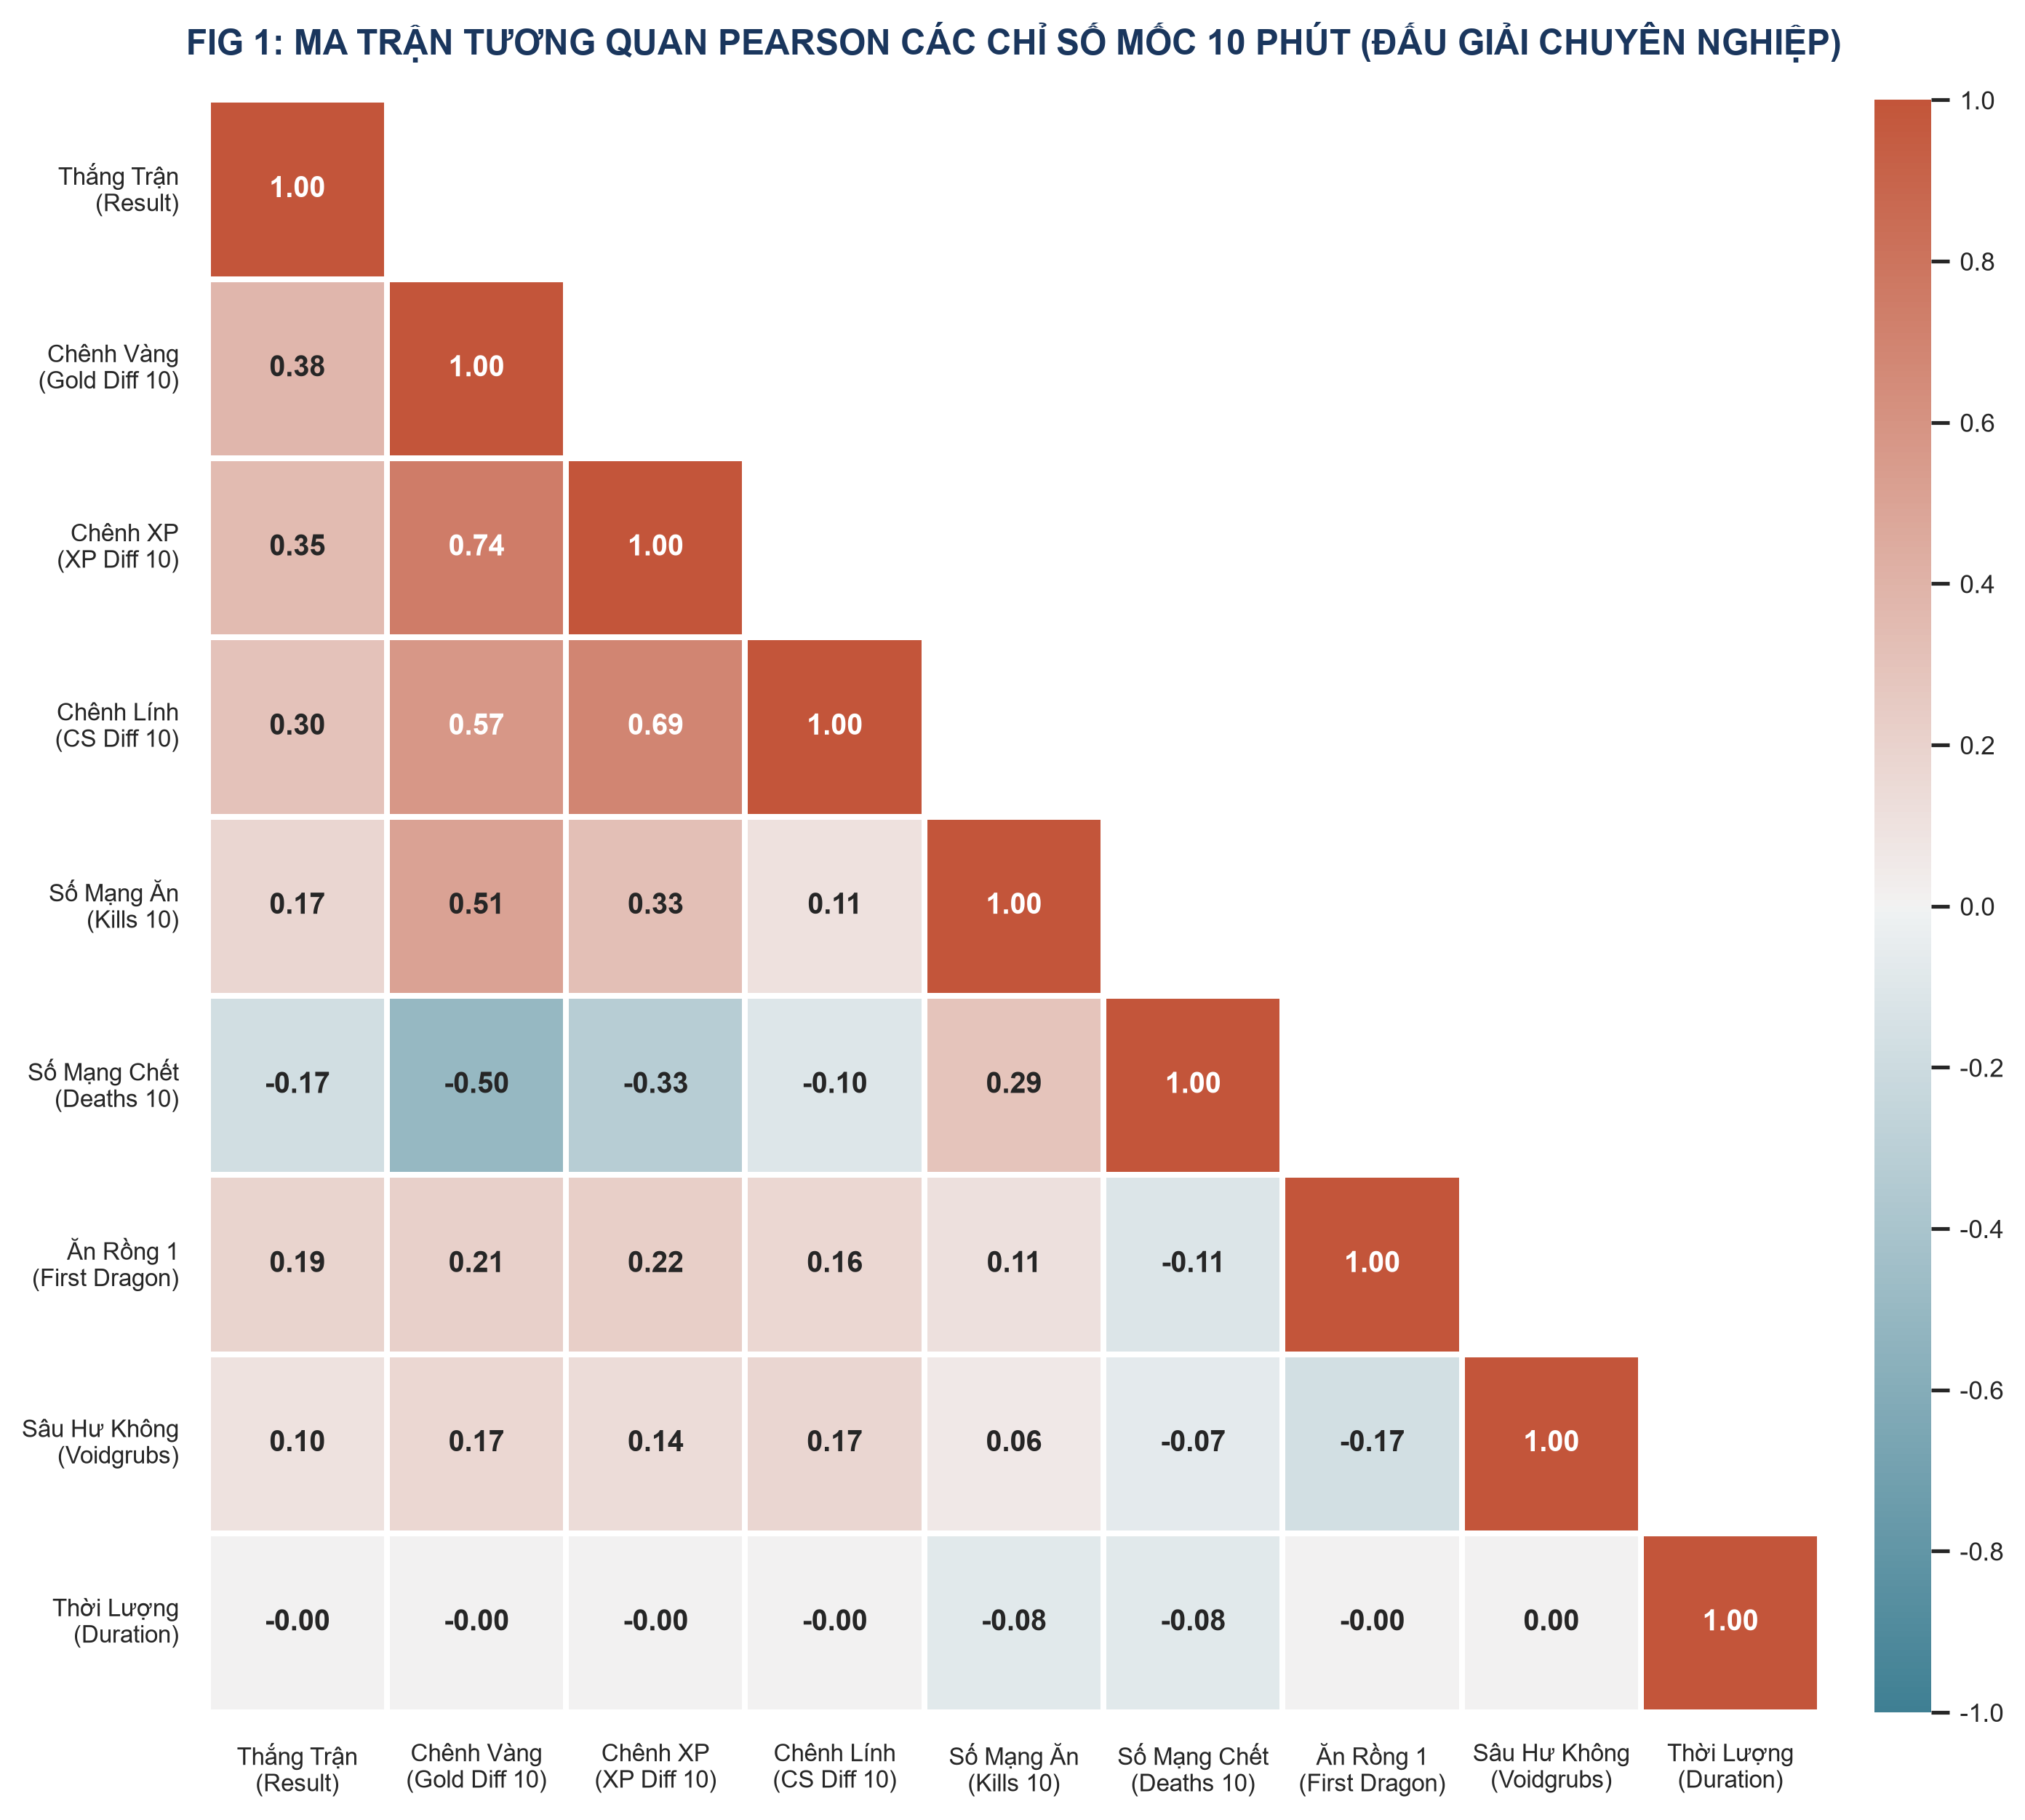

In [11]:
# -----------------------------------------------------------------------------
# FIG 1: MA TRẬN TƯƠNG QUAN PEARSON HEATMAP (9x9)
# -----------------------------------------------------------------------------
feature_cols = [
    'result', 'golddiffat10', 'xpdiffat10', 'csdiffat10',
    'killsat10', 'deathsat10', 'firstdragon', 'void_grubs', 'duration_min'
]
feature_labels = [
    'Thắng Trận\n(Result)', 'Chênh Vàng\n(Gold Diff 10)', 'Chênh XP\n(XP Diff 10)', 
    'Chênh Lính\n(CS Diff 10)', 'Số Mạng Ăn\n(Kills 10)', 'Số Mạng Chết\n(Deaths 10)', 
    'Ăn Rồng 1\n(First Dragon)', 'Sâu Hư Không\n(Voidgrubs)', 'Thời Lượng\n(Duration)'
]

corr_matrix = df_pro[feature_cols].corr()

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(10.5, 8.5), dpi=300)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    cmap = sns.diverging_palette(220, 20, as_cmap=True)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="3.5%", pad=0.25)

    sns.heatmap(
        corr_matrix, mask=mask, cmap=cmap, vmin=-1.0, vmax=1.0, center=0,
        annot=True, fmt=".2f", annot_kws={"size": 9.5, "weight": "bold"},
        square=True, linewidths=1.5, linecolor='white',
        cbar_ax=cax,
        cbar_kws={"ticks": [-1.0, -0.8, -0.6, -0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0]},
        xticklabels=feature_labels, yticklabels=feature_labels, ax=ax
    )

    ax.set_title("FIG 1: MA TRẬN TƯƠNG QUAN PEARSON CÁC CHỈ SỐ MỐC 10 PHÚT (ĐẤU GIẢI CHUYÊN NGHIỆP)", 
                 fontsize=11.5, fontweight='bold', pad=15, color='#1A365D')
    ax.set_xticklabels(feature_labels, rotation=0, fontsize=8, ha='center')
    ax.set_yticklabels(feature_labels, rotation=0, fontsize=8, va='center')
    ax.tick_params(left=False, bottom=False)
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    cax.tick_params(labelsize=8.5)

    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "fig1_correlation_heatmap.png", dpi=300, bbox_inches='tight')
    plt.show()


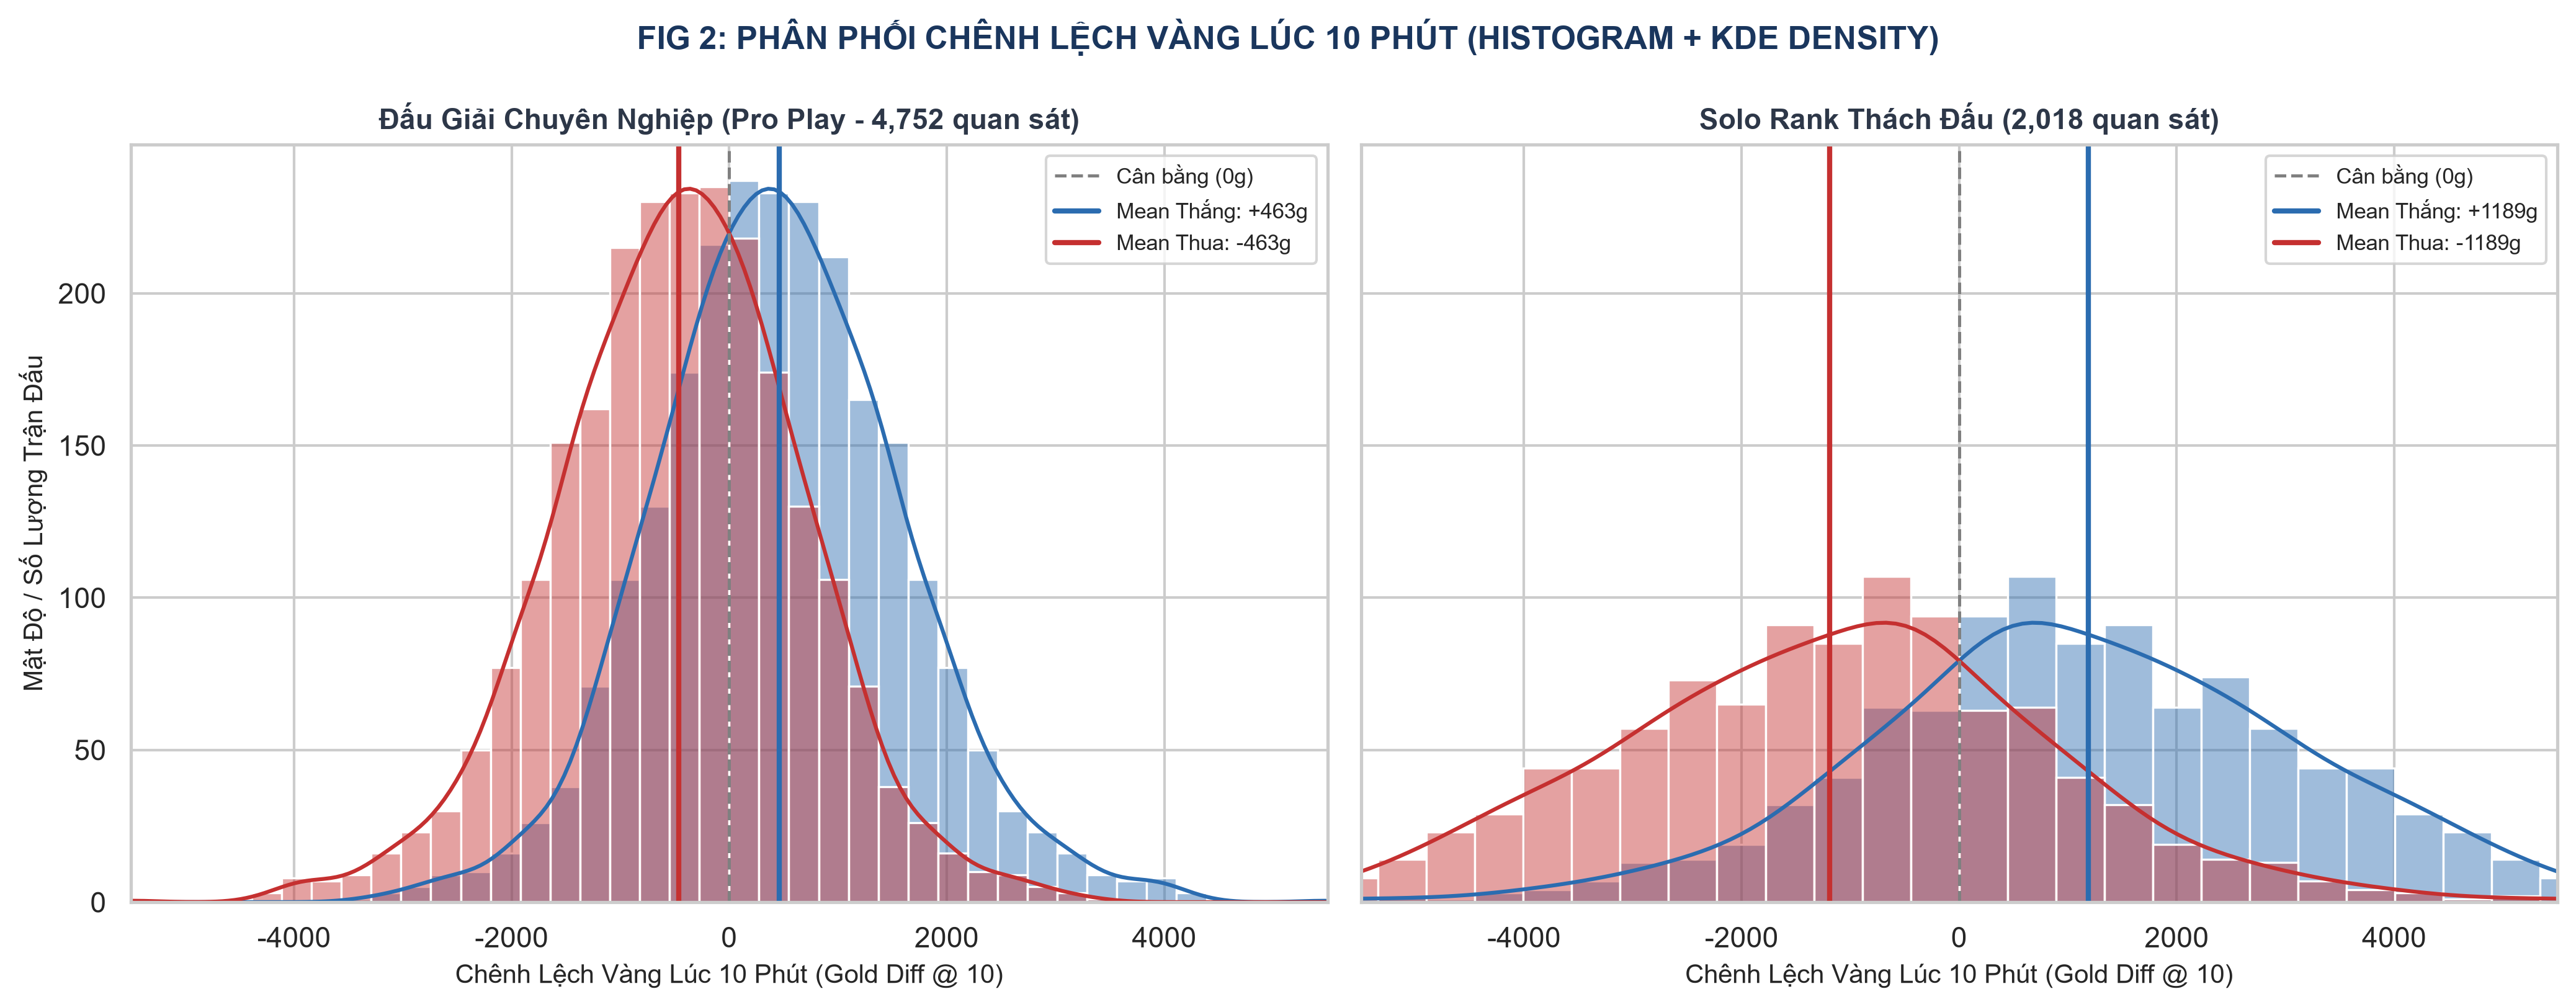

In [12]:
# -----------------------------------------------------------------------------
# FIG 2: PHÂN PHỐI CHÊNH LỆCH VÀNG LÚC 10 PHÚT (HISTOGRAM + KDE DENSITY)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300, sharey=True)

# 1. Pro Play
sns.histplot(
    data=df_pro, x='golddiffat10', hue='result', kde=True,
    palette={1: '#2B6CB0', 0: '#C53030'}, bins=40, alpha=0.45,
    ax=axes[0], legend=False
)
axes[0].axvline(0, color='gray', linestyle='--', linewidth=1.2, label='Cân bằng (0g)')
axes[0].axvline(df_pro[df_pro['result']==1]['golddiffat10'].mean(), color='#2B6CB0', linestyle='-', linewidth=2, label=f"Mean Thắng: +{df_pro[df_pro['result']==1]['golddiffat10'].mean():.0f}g")
axes[0].axvline(df_pro[df_pro['result']==0]['golddiffat10'].mean(), color='#C53030', linestyle='-', linewidth=2, label=f"Mean Thua: {df_pro[df_pro['result']==0]['golddiffat10'].mean():.0f}g")
axes[0].set_title("Đấu Giải Chuyên Nghiệp (Pro Play - 4,752 quan sát)", fontsize=11, fontweight='bold', color='#2D3748')
axes[0].set_xlabel("Chênh Lệch Vàng Lúc 10 Phút (Gold Diff @ 10)", fontsize=10)
axes[0].set_ylabel("Mật Độ / Số Lượng Trận Đấu", fontsize=10)
axes[0].legend(loc='upper right', frameon=True, fontsize=8.5)
axes[0].set_xlim(-5500, 5500)

# 2. Solo Rank
df_rank_blue_diff = pd.DataFrame({'golddiff': df_rank['blueGoldDiff'], 'result': df_rank['blueWins']})
df_rank_red_diff = pd.DataFrame({'golddiff': -df_rank['blueGoldDiff'], 'result': 1 - df_rank['blueWins']})
df_rank_all_diff = pd.concat([df_rank_blue_diff, df_rank_red_diff], ignore_index=True)

sns.histplot(
    data=df_rank_all_diff, x='golddiff', hue='result', kde=True,
    palette={1: '#2B6CB0', 0: '#C53030'}, bins=40, alpha=0.45,
    ax=axes[1], legend=False
)
axes[1].axvline(0, color='gray', linestyle='--', linewidth=1.2, label='Cân bằng (0g)')
axes[1].axvline(df_rank_all_diff[df_rank_all_diff['result']==1]['golddiff'].mean(), color='#2B6CB0', linestyle='-', linewidth=2, label=f"Mean Thắng: +{df_rank_all_diff[df_rank_all_diff['result']==1]['golddiff'].mean():.0f}g")
axes[1].axvline(df_rank_all_diff[df_rank_all_diff['result']==0]['golddiff'].mean(), color='#C53030', linestyle='-', linewidth=2, label=f"Mean Thua: {df_rank_all_diff[df_rank_all_diff['result']==0]['golddiff'].mean():.0f}g")
axes[1].set_title("Solo Rank Thách Đấu (2,018 quan sát)", fontsize=11, fontweight='bold', color='#2D3748')
axes[1].set_xlabel("Chênh Lệch Vàng Lúc 10 Phút (Gold Diff @ 10)", fontsize=10)
axes[1].legend(loc='upper right', frameon=True, fontsize=8.5)
axes[1].set_xlim(-5500, 5500)

fig.suptitle("FIG 2: PHÂN PHỐI CHÊNH LỆCH VÀNG LÚC 10 PHÚT (HISTOGRAM + KDE DENSITY)", fontsize=12.5, fontweight='bold', y=0.98, color='#1A365D')
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_gold_diff_distribution_kde.png", dpi=300)
plt.show()


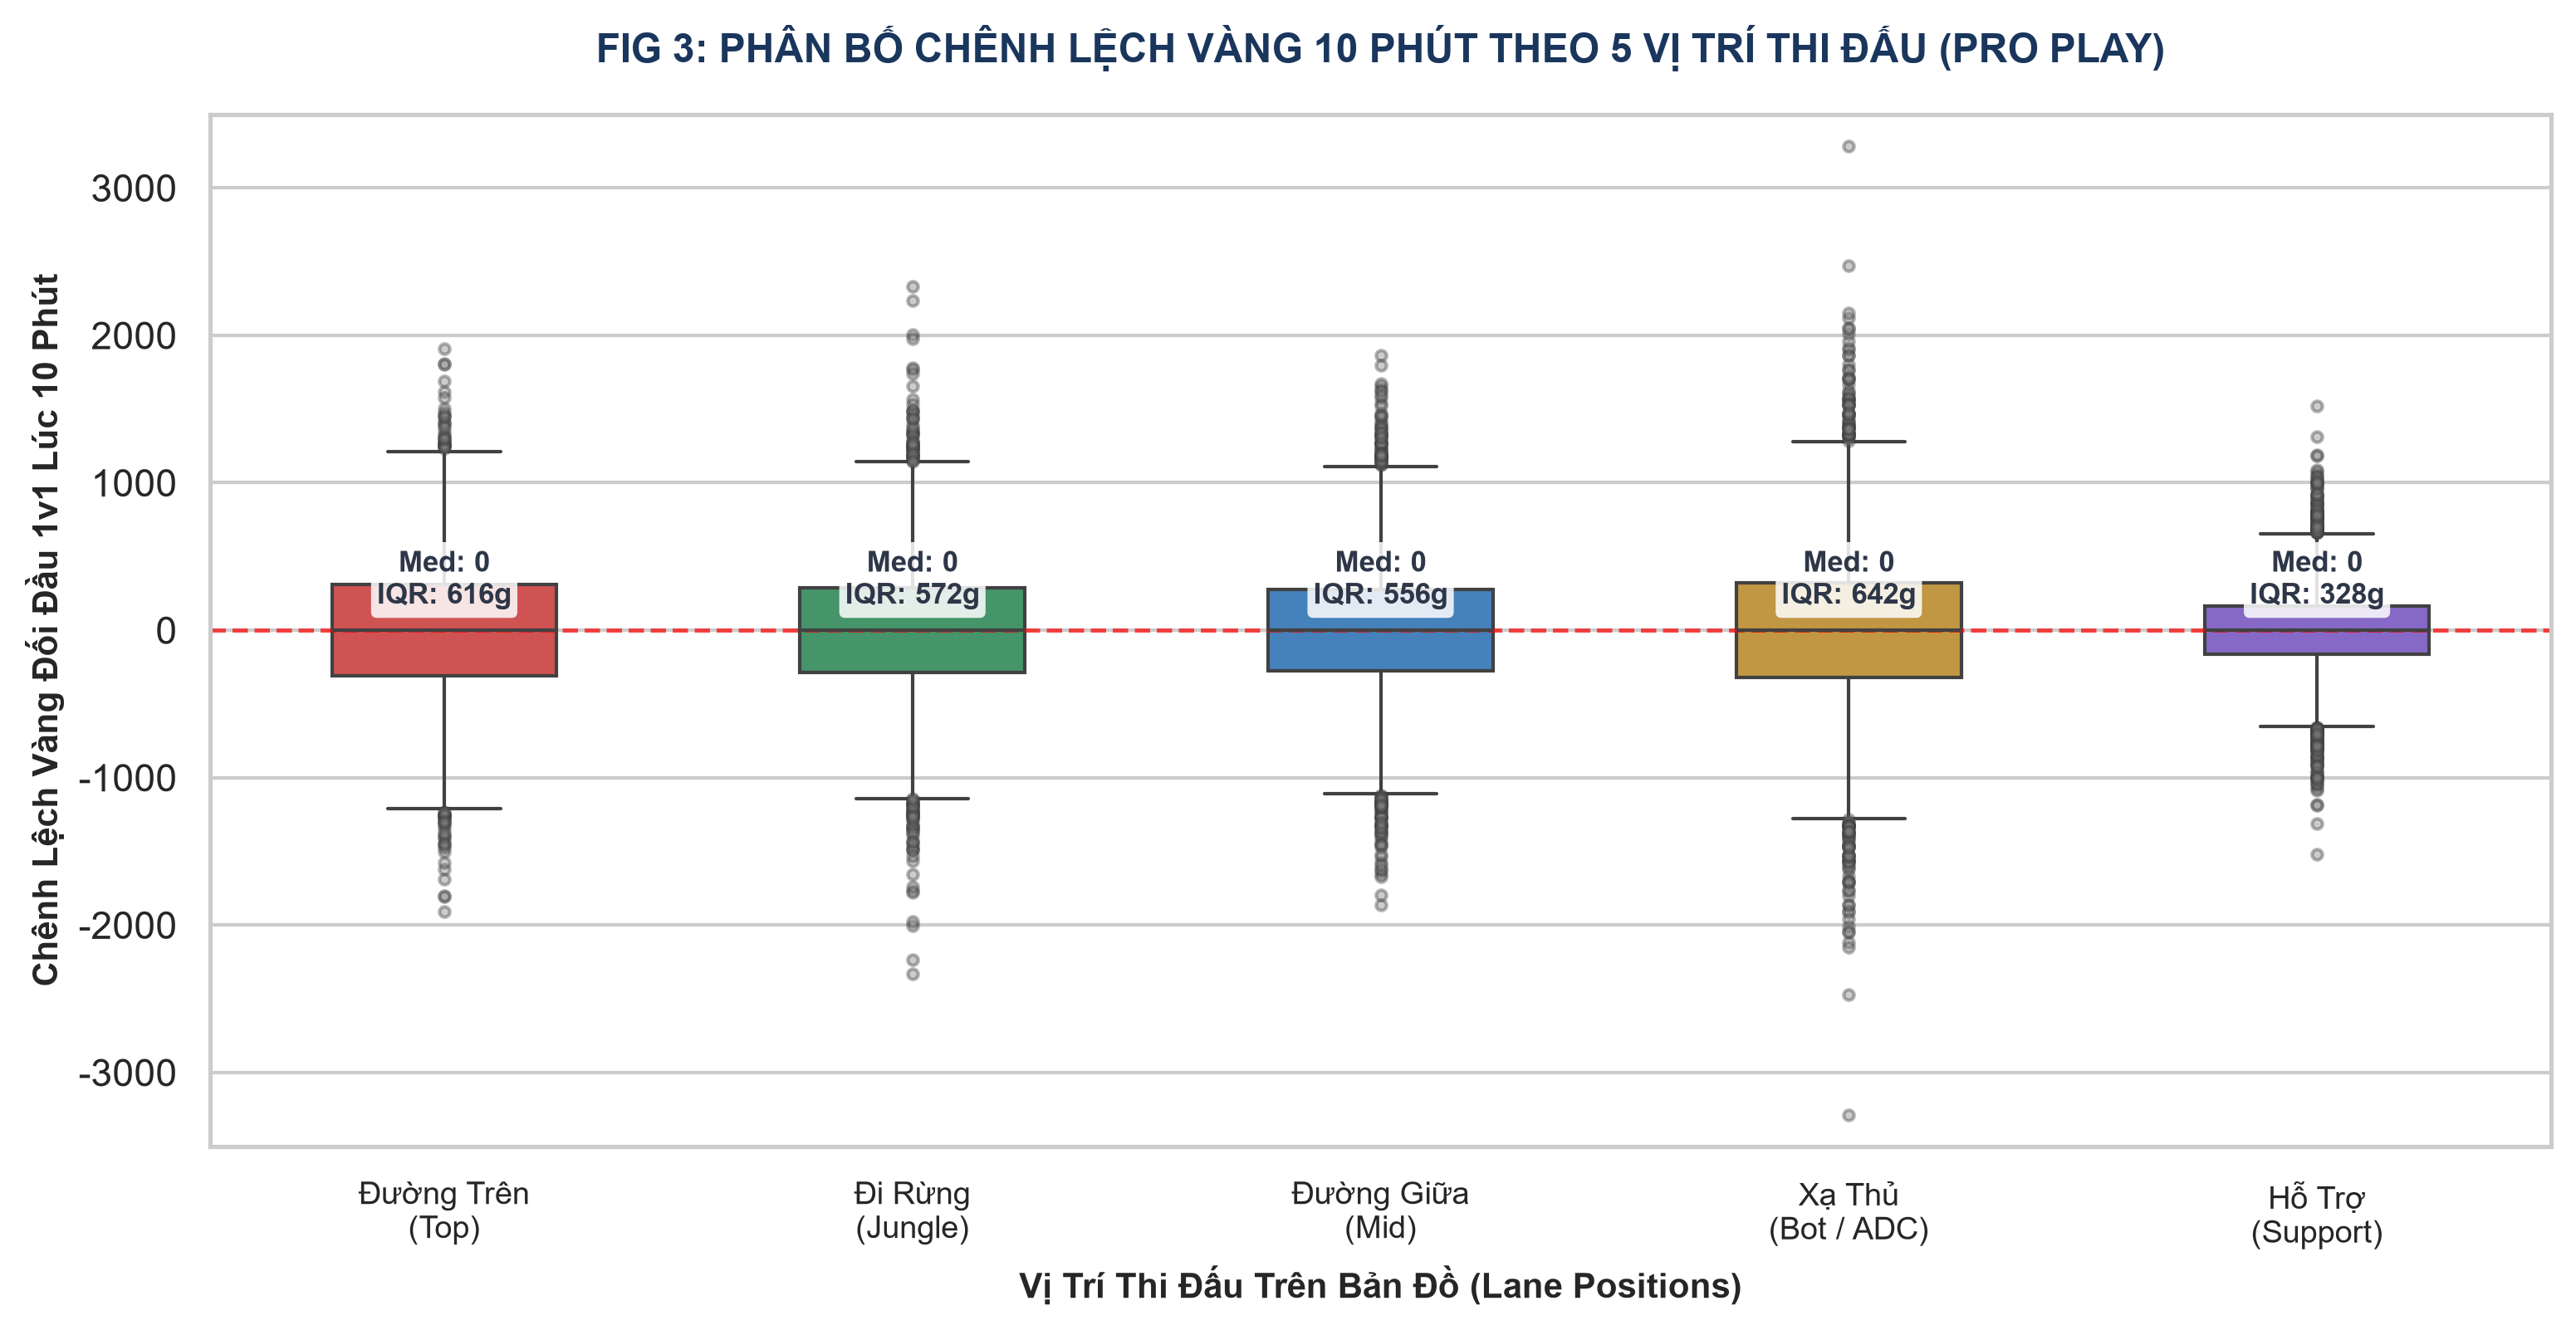

In [13]:
# -----------------------------------------------------------------------------
# FIG 3: PHÂN BỐ KINH TẾ 5 VỊ TRÍ THI ĐẤU LÚC 10 PHÚT (BOXPLOT & OUTLIERS)
# -----------------------------------------------------------------------------
df_players = pd.read_sql_query("""
SELECT p.position, p.golddiffat10
FROM tournament_players p
JOIN tournament_matches m ON p.gameid = m.gameid AND p.side = m.side
WHERE m.datacompleteness = 'complete'
""", conn)

pos_order = ['top', 'jng', 'mid', 'bot', 'sup']
pos_labels = ['Đường Trên\n(Top)', 'Đi Rừng\n(Jungle)', 'Đường Giữa\n(Mid)', 'Xạ Thủ\n(Bot / ADC)', 'Hỗ Trợ\n(Support)']
df_plot_pos = df_players[df_players['position'].isin(pos_order)].copy()

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=300)
colors = ['#E53E3E', '#38A169', '#3182CE', '#D69E2E', '#805AD5']

sns.boxplot(
    data=df_plot_pos, x='position', y='golddiffat10', order=pos_order,
    palette=colors, width=0.48, fliersize=3,
    flierprops={'marker': 'o', 'markerfacecolor': 'gray', 'alpha': 0.4},
    ax=ax
)
ax.axhline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.7)

medians = df_plot_pos.groupby('position')['golddiffat10'].median()[pos_order]
iqrs = df_plot_pos.groupby('position')['golddiffat10'].apply(lambda x: x.quantile(0.75) - x.quantile(0.25))[pos_order]

for i, (med, iqr_val) in enumerate(zip(medians, iqrs)):
    ax.text(i, med + 180, f"Med: {med:.0f}\nIQR: {iqr_val:.0f}g", 
            ha='center', fontsize=8.5, fontweight='bold', color='#2D3748',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='none'))

ax.set_title("FIG 3: PHÂN BỐ CHÊNH LỆCH VÀNG 10 PHÚT THEO 5 VỊ TRÍ THI ĐẤU (PRO PLAY)", fontsize=11.5, fontweight='bold', pad=15, color='#1A365D')
ax.set_xlabel("Vị Trí Thi Đấu Trên Bản Đồ (Lane Positions)", fontsize=10, fontweight='bold')
ax.set_ylabel("Chênh Lệch Vàng Đối Đầu 1v1 Lúc 10 Phút", fontsize=10, fontweight='bold')
ax.set_xticks(range(len(pos_labels)))
ax.set_xticklabels(pos_labels, fontsize=9)
ax.set_ylim(-3500, 3500)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_lane_economy_boxplot.png", dpi=300)
plt.show()


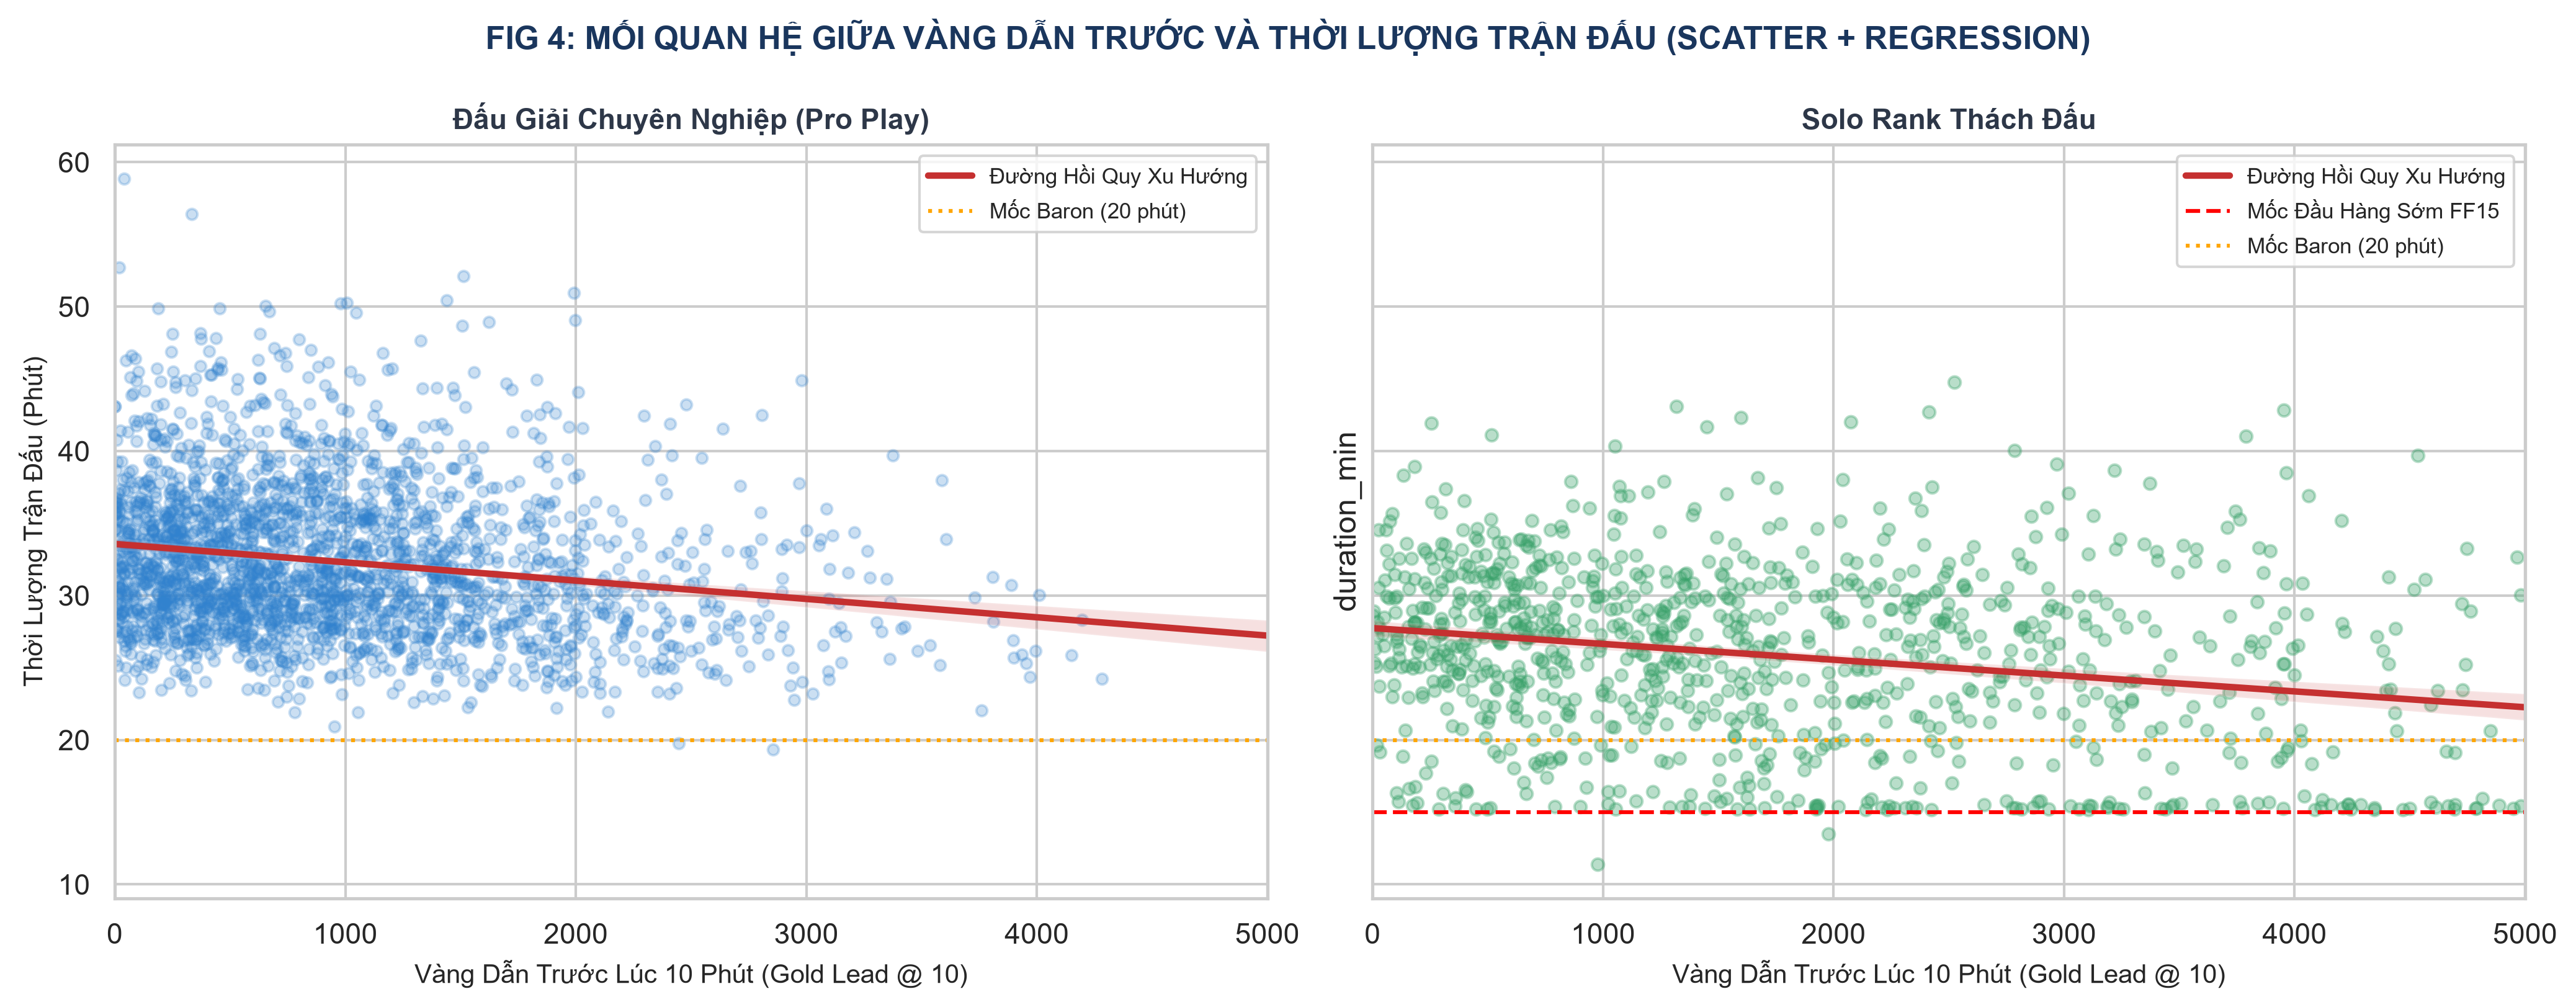

In [14]:
# -----------------------------------------------------------------------------
# FIG 4: VÀNG DẪN TRƯỚC VS THỜI LƯỢNG TRẬN ĐẤU (SCATTER + REGRESSION)
# -----------------------------------------------------------------------------
df_pro_lead = df_pro[df_pro['golddiffat10'] >= 0].copy()

df_rank_blue_lead = df_rank[df_rank['blueGoldDiff'] >= 0].copy()
df_rank_blue_lead['lead_gold'] = df_rank_blue_lead['blueGoldDiff']
df_rank_red_lead = df_rank[df_rank['blueGoldDiff'] < 0].copy()
df_rank_red_lead['lead_gold'] = -df_rank_red_lead['blueGoldDiff']
df_rank_lead = pd.concat([df_rank_blue_lead, df_rank_red_lead], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300, sharey=True)

# 1. Pro Play
sns.regplot(
    data=df_pro_lead, x='golddiffat10', y='duration_min',
    scatter_kws={'alpha': 0.25, 'color': '#3182CE', 's': 18},
    line_kws={'color': '#C53030', 'linewidth': 2.5, 'label': 'Đường Hồi Quy Xu Hướng'},
    ax=axes[0]
)
axes[0].axhline(20, color='orange', linestyle=':', label='Mốc Baron (20 phút)')
axes[0].set_title("Đấu Giải Chuyên Nghiệp (Pro Play)", fontsize=11, fontweight='bold', color='#2D3748')
axes[0].set_xlabel("Vàng Dẫn Trước Lúc 10 Phút (Gold Lead @ 10)", fontsize=10)
axes[0].set_ylabel("Thời Lượng Trận Đấu (Phút)", fontsize=10)
axes[0].legend(loc='upper right', frameon=True, fontsize=8.5)
axes[0].set_xlim(0, 5000)

# 2. Solo Rank
sns.regplot(
    data=df_rank_lead, x='lead_gold', y='duration_min',
    scatter_kws={'alpha': 0.35, 'color': '#38A169', 's': 22},
    line_kws={'color': '#C53030', 'linewidth': 2.5, 'label': 'Đường Hồi Quy Xu Hướng'},
    ax=axes[1]
)
axes[1].axhline(15, color='red', linestyle='--', label='Mốc Đầu Hàng Sớm FF15')
axes[1].axhline(20, color='orange', linestyle=':', label='Mốc Baron (20 phút)')
axes[1].set_title("Solo Rank Thách Đấu", fontsize=11, fontweight='bold', color='#2D3748')
axes[1].set_xlabel("Vàng Dẫn Trước Lúc 10 Phút (Gold Lead @ 10)", fontsize=10)
axes[1].legend(loc='upper right', frameon=True, fontsize=8.5)
axes[1].set_xlim(0, 5000)

fig.suptitle("FIG 4: MỐI QUAN HỆ GIỮA VÀNG DẪN TRƯỚC VÀ THỜI LƯỢNG TRẬN ĐẤU (SCATTER + REGRESSION)", fontsize=12.5, fontweight='bold', y=0.98, color='#1A365D')
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig4_gold_lead_vs_duration_scatter.png", dpi=300)
plt.show()


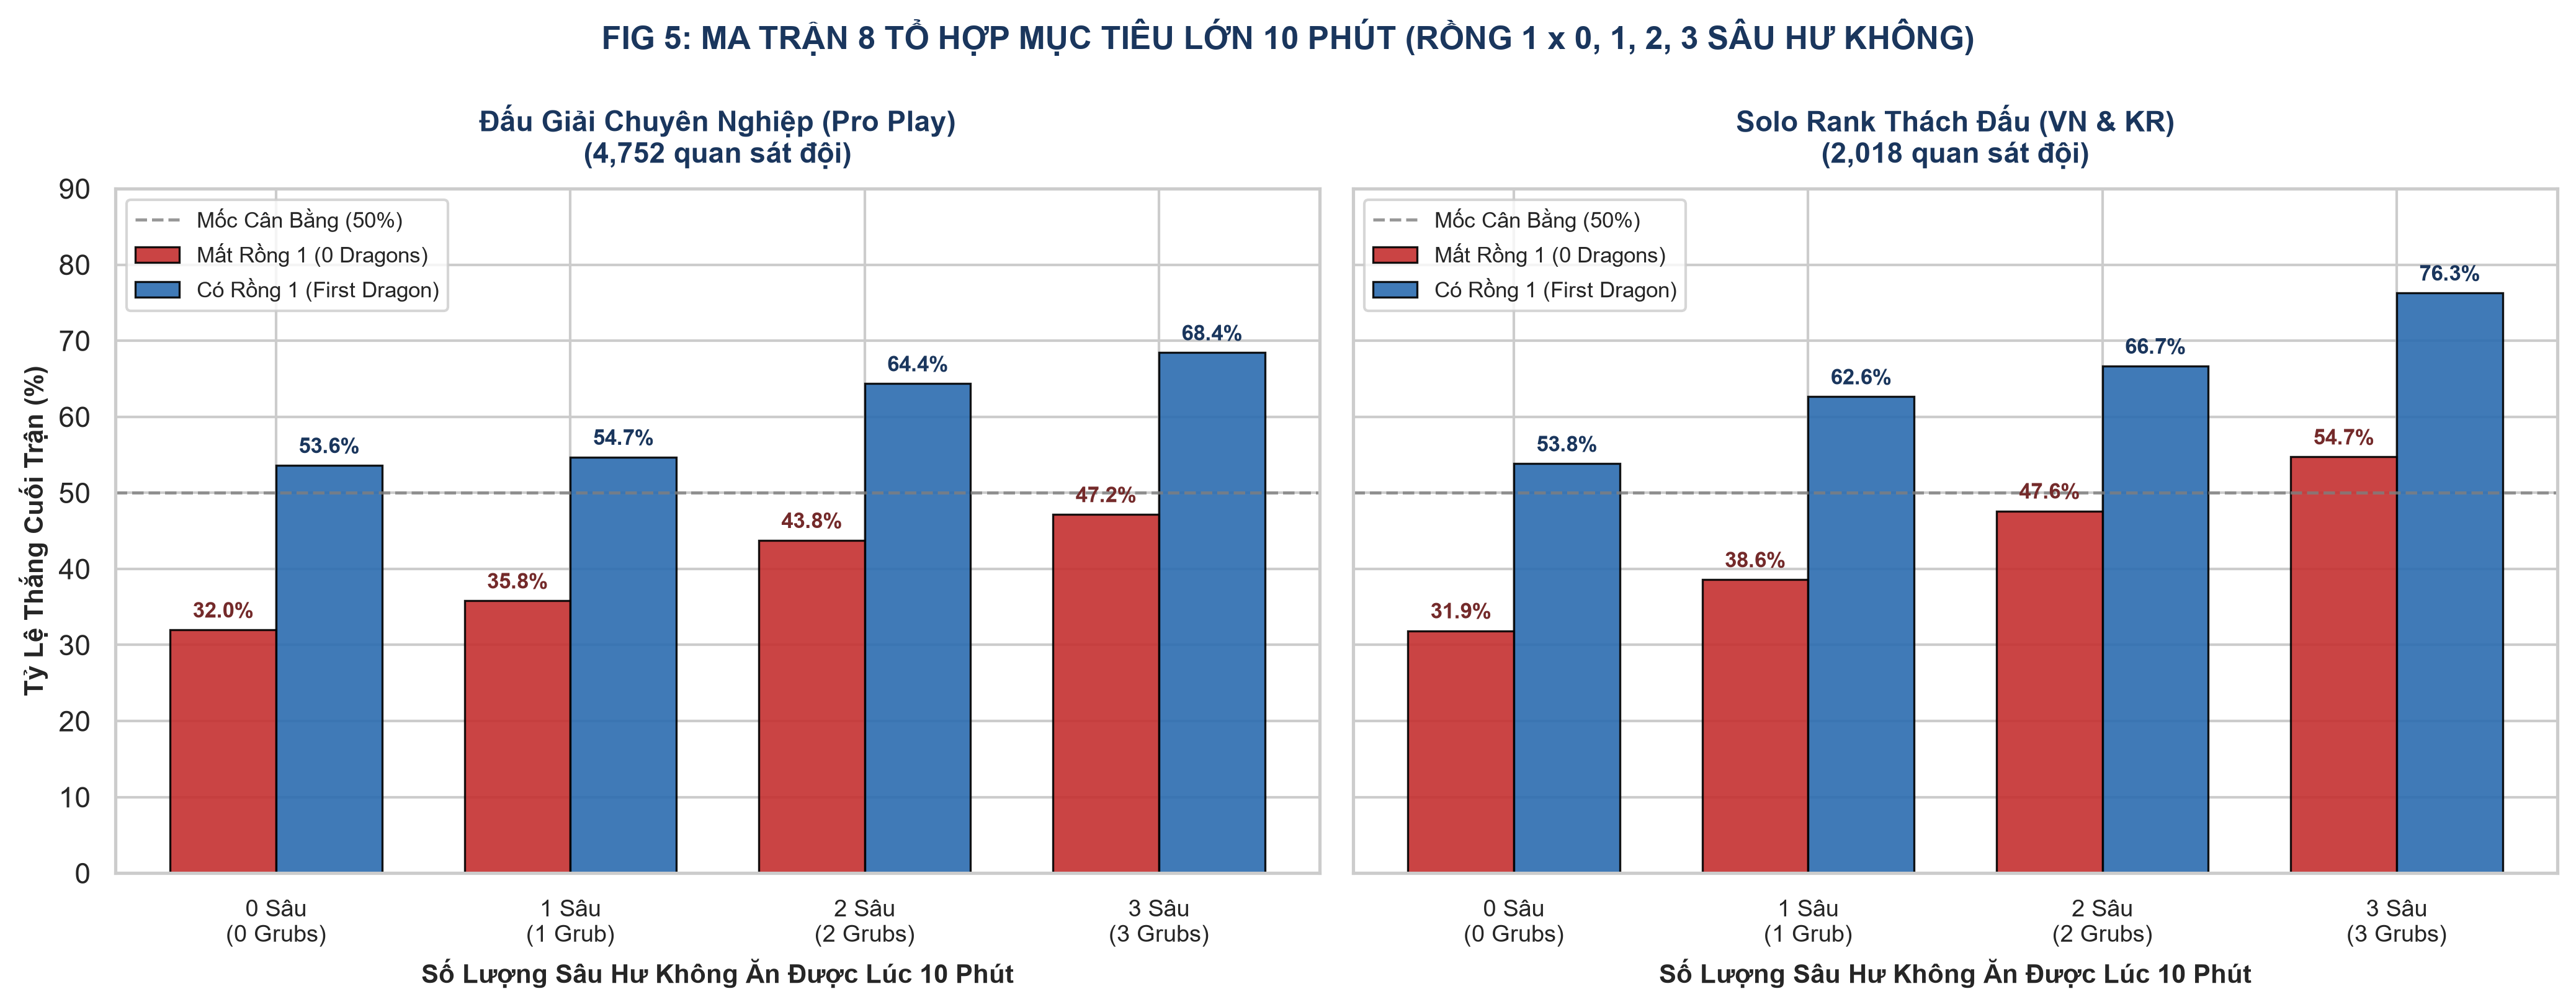

In [15]:
# -----------------------------------------------------------------------------
# FIG 5: MA TRẬN 8 TỔ HỢP MỤC TIÊU LỚN 10 PHÚT (RỒNG 1 x 0, 1, 2, 3 SÂU)
# -----------------------------------------------------------------------------
df_pro_work = df_pro[df_pro['void_grubs'].isin([0, 1, 2, 3])].copy()
df_pro_work['has_drag'] = df_pro_work['firstdragon'].fillna(0).astype(int)
pro_stats = df_pro_work.groupby(['has_drag', 'void_grubs'])['result'].mean() * 100.0

df_rank_blue_sc = pd.DataFrame({
    'has_drag': (df_rank['blueDragons'] > 0).astype(int),
    'void_grubs': df_rank['blueVoidgrubs'].clip(0, 3),
    'result': df_rank['blueWins']
})
df_rank_red_sc = pd.DataFrame({
    'has_drag': (df_rank['redDragons'] > 0).astype(int),
    'void_grubs': df_rank['redVoidgrubs'].clip(0, 3),
    'result': 1 - df_rank['blueWins']
})
df_rank_all_sc = pd.concat([df_rank_blue_sc, df_rank_red_sc], ignore_index=True)
rank_stats = df_rank_all_sc.groupby(['has_drag', 'void_grubs'])['result'].mean() * 100.0

grub_labels = ['0 Sâu\n(0 Grubs)', '1 Sâu\n(1 Grub)', '2 Sâu\n(2 Grubs)', '3 Sâu\n(3 Grubs)']
x = np.arange(len(grub_labels))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300, sharey=True)

def draw_subplot(ax, stats_map, title, subtitle):
    no_drag = [stats_map.get((0, g), 0.0) for g in range(4)]
    has_drag = [stats_map.get((1, g), 0.0) for g in range(4)]

    rects_no = ax.bar(x - width/2, no_drag, width, label='Mất Rồng 1 (0 Dragons)', color='#C53030', alpha=0.9, edgecolor='black', linewidth=0.8)
    rects_has = ax.bar(x + width/2, has_drag, width, label='Có Rồng 1 (First Dragon)', color='#2B6CB0', alpha=0.9, edgecolor='black', linewidth=0.8)
    ax.axhline(50, color='gray', linestyle='--', linewidth=1.2, alpha=0.8, label='Mốc Cân Bằng (50%)')

    for rect in rects_no:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#742A2A')

    for rect in rects_has:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1A365D')

    ax.set_title(f"{title}\n({subtitle})", fontsize=11, fontweight='bold', color='#1A365D', pad=10)
    ax.set_xlabel("Số Lượng Sâu Hư Không Ăn Được Lúc 10 Phút", fontsize=10, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(grub_labels, fontsize=9)
    ax.set_ylim(0, 90)
    ax.legend(loc='upper left', frameon=True, fontsize=8.5)

draw_subplot(axes[0], pro_stats, "Đấu Giải Chuyên Nghiệp (Pro Play)", "4,752 quan sát đội")
draw_subplot(axes[1], rank_stats, "Solo Rank Thách Đấu (VN & KR)", "2,018 quan sát đội")
axes[0].set_ylabel("Tỷ Lệ Thắng Cuối Trận (%)", fontsize=10, fontweight='bold')

fig.suptitle("FIG 5: MA TRẬN 8 TỔ HỢP MỤC TIÊU LỚN 10 PHÚT (RỒNG 1 x 0, 1, 2, 3 SÂU HƯ KHÔNG)", fontsize=12.5, fontweight='bold', y=0.98, color='#1A365D')
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig5_neutral_objectives_scenarios_bar.png", dpi=300)
plt.show()


---
## 5. TỔNG KẾT INSIGHTS KHOA HỌC & CHUYỂN GIAO CHO GIAI ĐOẠN 3 (MACHINE LEARNING)

### 🎯 5 Phát Hiện Chiến Thuật Cốt Lõi Từ Dữ Liệu Thực Nghiệm:
1. **Lợi thế Phe Xanh:** Tồn tại thực sự ở Đấu Giải (53.50% thắng, p = 0.0001) nhờ lợi thế First Pick và góc nhìn camera. Ở Solo Rank, Phe Đỏ thắng 54.51% do Riot Matchmaking dồn MMR cao sang Phe Đỏ.
2. **Quy luật Snowball:** Dẫn >= 2,000 vàng lúc 10 phút mang lại **~85% tỷ lệ thắng áp đảo** ở cả 2 môi trường. Tuy nhiên, trận Solo Rank kết thúc nhanh hơn trung bình 5.3 phút do cơ chế FF15 và giao tranh liên tục.
3. **Ưu tiên Mục tiêu Trung lập:** Ở Đấu Giải, **Rồng 1 vượt trội hơn 3 Sâu Hư Không** (Odds Ratio = 2.15 vs 1.43). Kèo chia sâu (1 Rồng + 1 Sâu) thắng áp đảo kèo (0 Rồng + 2 Sâu) (54.69% vs 43.75%).
4. **Phân hóa Đường Thi Đấu:** Khu vực **Xạ Thủ (Bot: IQR = 642g)** và **Đường Trên (Top: IQR = 616g)** có mức độ giãn tiền và rủi ro ngoại lai cao nhất bản đồ.
5. **Thời lượng Trận đấu:** Tương quan nghịch rõ rệt với lượng tiền dẫn trước (r = -0.31). Đấu Giải bị chặn đáy ở mốc 20 phút (Baron), trong khi Solo Rank có nhiều trận kết thúc ở phút 15-18 (FF15).

---

### 🚀 Định Hướng Kỹ Thuật Cho Giai Đoạn 3 (Machine Learning 2 Giai Đoạn):
* **Mô hình Draft AI (Phút 0):** Huấn luyện trên tập `clean_tournament_draft.csv` (3,000 trận cấm/chọn) kết hợp vector hóa đặc trưng tướng và trọng số thời gian.
* **Mô hình Snowball AI (Phút 10):** Đưa `golddiffat10`, `xpdiffat10`, `killsat10`, `firstdragon`, `void_grubs` làm các đặc trưng cốt lõi cho Random Forest & XGBoost (kỳ vọng Accuracy > 80%).
* **Phân cụm K-Means & PCA (Chương 4):** Nhận diện 4 trường phái đội hình và xuất Thẻ Điều Kiện Thắng (Win Condition Card) tự động.
